# Embeddings — Modern External Dataset Evaluation

**Purpose:** Evaluate three already-trained HC3 classifiers using sentence-transformer embeddings of the **same 600 modern external answers** used in the TF-IDF evaluation.

- Logistic Regression, Linear SVM, and feed-forward neural network.
- Use the original pretrained encoder from `models/embeddings/embedding_metadata.json`.
- The saved `train_embeddings.npy`, `validation_embeddings.npy`, and `test_embeddings.npy` belong to HC3; they are **not** the modern inputs.
- Output separate CSV files in `data/evaluation/` for later six-model comparison.
-


## 1. Imports and project paths

In [11]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sentence_transformers import SentenceTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# Works when Jupyter starts in the repo root OR notebooks/evaluation.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents]
                     if (p / 'models').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run Jupyter from inside the Spot-the-Bot repository.')
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
EMBEDDINGS_DIR = PROJECT_ROOT / 'models' / 'embeddings'
RESULTS_DIR = PROJECT_ROOT / 'data' / 'evaluation'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)

Project root: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text


## 2. Load modern responses and verify labels

This loads **new external answers**, not the HC3 training/validation/test arrays. The modern data is not used to fit anything.

In [12]:
modern_path = PROCESSED_DIR / 'modern_dataset_drift_eval.csv'
if not modern_path.exists():
    raise FileNotFoundError(f'Move the modern CSV here: {modern_path}')
modern = pd.read_csv(modern_path).rename(columns={
    'answer': 'text', 'question_id': 'id', 'source': 'question_source'
})
required = {'text', 'id', 'label', 'model'}
assert required.issubset(modern.columns), f'Missing columns: {required - set(modern.columns)}'
assert modern['label'].isin(['human', 'ai']).all(), 'Unexpected class labels'
modern['target'] = modern['label'].map({'human': 0, 'ai': 1}).astype(int)
assert modern['text'].notna().all() and modern['text'].astype(str).str.strip().ne('').all()
assert modern['id'].notna().all()
assert len(modern) == 600 and modern['id'].nunique() == 150
assert modern.groupby('id').size().eq(4).all()
print('Rows:', len(modern), '| Questions:', modern['id'].nunique())
print(pd.crosstab(modern['model'], modern['target']))
display(modern[['id', 'model', 'label', 'target', 'text']].head())

Rows: 600 | Questions: 150
target     0    1
model            
chatgpt    0  150
claude     0  150
gemini     0  150
human    150    0


,id,model,label,target,text
0,26756,human,human,0,So why is the ocean so clean? You can drink it...
1,26756,chatgpt,ai,1,The ocean is not actually “clean” in the sense...
2,26756,claude,ai,1,"The ocean isn't as clean as it looks, but you'..."
3,26756,gemini,ai,1,Wastewater and organic waste undergo municipal...
4,26764,human,human,0,"CO2, O3, and CH4, which constitute, in combina..."


## 3. Check for exact-answer overlap with HC3

A matching response in HC3 could compromise the external evaluation. This is an exact normalized-text audit, not a comprehensive semantic leakage check.

In [13]:
from hashlib import sha256

def fingerprint(text):
    return sha256(' '.join(str(text).split()).strip().casefold().encode('utf-8')).hexdigest()

modern_hashes = modern['text'].map(fingerprint)
known_hashes = set()
found_splits = []
for split in ('train', 'validation', 'test'):
    path = PROCESSED_DIR / f'{split}.csv'
    if path.exists():
        old = pd.read_csv(path, usecols=['text'])
        known_hashes.update(old['text'].dropna().map(fingerprint))
        found_splits.append(split)
if not found_splits:
    print('HC3 split CSVs not found; overlap audit not performed.')
else:
    overlap = modern_hashes.isin(known_hashes)
    print('HC3 splits checked:', found_splits)
    print('Exact overlapping answers:', int(overlap.sum()))
    if overlap.any():
        display(modern.loc[overlap, ['id', 'model', 'text']].head())
        print('WARNING: Investigate overlaps before interpreting external metrics.')

HC3 splits checked: ['train', 'validation', 'test']
Exact overlapping answers: 0


## 4. Shared metrics and model loading

ROC-AUC uses continuous scores (SVM margins are **not probabilities**). Classification metrics use the saved model decision rule, or the saved FFNN threshold.

In [14]:
def evaluate(name, scores, predictions):
    scores = np.asarray(scores, dtype=float).ravel()
    predictions = np.asarray(predictions, dtype=int).ravel()
    y = modern['target'].to_numpy()
    assert len(scores) == len(y) == len(predictions)
    assert np.isfinite(scores).all()
    assert set(np.unique(predictions)).issubset({0, 1})
    metrics = {
        'model': name,
        'accuracy': accuracy_score(y, predictions),
        'macro_precision': precision_score(y, predictions, average='macro', zero_division=0),
        'macro_recall': recall_score(y, predictions, average='macro', zero_division=0),
        'macro_f1': f1_score(y, predictions, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(y, scores),
        'human_false_positive_rate': float(predictions[y == 0].mean()),
    }
    print(f'\n{name} — modern external evaluation')
    print(pd.Series(metrics).to_string())
    print(classification_report(y, predictions, labels=[0, 1],
                                target_names=['Human', 'AI'], zero_division=0))
    return metrics

results = []
all_scores = {}
all_predictions = {}

def record(name, scores, predictions):
    results.append(evaluate(name, scores, predictions))
    all_scores[name] = np.asarray(scores).ravel()
    all_predictions[name] = np.asarray(predictions).ravel()

def load_sklearn(path):
    if not path.exists():
        print(f'SKIP — missing artifact: {path}')
        return None
    artifact = joblib.load(path)
    return artifact['classifier'] if isinstance(artifact, dict) and 'classifier' in artifact else artifact


## 5. Encode the modern dataset and evaluate three saved embedding models

This may take a little time while the pretrained sentence transformer encodes all 600 responses. The encoder is **not trained** here. The saved classifiers are loaded and used only for predictions.


In [15]:
metadata_path = EMBEDDINGS_DIR / 'embedding_metadata.json'
if not metadata_path.exists():
    raise FileNotFoundError(f'Missing original encoder metadata: {metadata_path}')
metadata = json.loads(metadata_path.read_text())
model_name = metadata['model_name']
print('Original encoder:', model_name)
encoder = SentenceTransformer(model_name)
X_modern_embeddings = encoder.encode(
    modern['text'].astype(str).tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False,
)
assert X_modern_embeddings.shape[0] == len(modern)
assert X_modern_embeddings.shape[1] == int(metadata['embedding_dimension'])
print('Modern embedding features:', X_modern_embeddings.shape)

for name, filename, score_method in [
    ('Embeddings Logistic Regression', 'logistic_regression_embeddings.joblib', 'predict_proba'),
    ('Embeddings Linear SVM', 'linear_svm_embeddings.joblib', 'decision_function'),
]:
    clf = load_sklearn(EMBEDDINGS_DIR / filename)
    if clf is None:
        continue
    predictions = clf.predict(X_modern_embeddings)
    if score_method == 'predict_proba':
        ai_index = list(clf.classes_).index(1)
        scores = clf.predict_proba(X_modern_embeddings)[:, ai_index]
    else:
        scores = clf.decision_function(X_modern_embeddings)
        if list(clf.classes_)[-1] != 1:
            scores = -scores
    record(name, scores, predictions)

ffnn_path = EMBEDDINGS_DIR / 'feedforward_neural_network_embeddings.keras'
if ffnn_path.exists():
    ffnn = keras.models.load_model(ffnn_path, compile=False)
    assert X_modern_embeddings.shape[1] == ffnn.input_shape[-1], 'Embedding FFNN dimension mismatch'
    scores = ffnn.predict(X_modern_embeddings, batch_size=64, verbose=0).ravel()
    # Training notebook uses sigmoid with the default 0.5 threshold.
    record('Embeddings FFNN', scores, (scores >= 0.5).astype(int))
else:
    print('SKIP — missing embedding FFNN:', ffnn_path)


Original encoder: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Modern embedding features: (600, 384)

Embeddings Logistic Regression — modern external evaluation
model                        Embeddings Logistic Regression
accuracy                                           0.383333
macro_precision                                    0.533994
macro_recall                                       0.531111
macro_f1                                           0.382778
roc_auc                                            0.543763
human_false_positive_rate                          0.173333
              precision    recall  f1-score   support

       Human       0.26      0.83      0.40       150
          AI       0.80      0.24      0.36       450

    accuracy                           0.38       600
   macro avg       0.53      0.53      0.38       600
weighted avg       0.67      0.38      0.37       600


Embeddings Linear SVM — modern external evaluation
model                        Embeddings Linear SVM
accuracy                                     0.375


In [16]:
import numpy as np

# Load a small sample of the original saved HC3 embeddings
original_embeddings = np.load(
    EMBEDDINGS_DIR / "test_embeddings.npy",
    mmap_mode="r"
)

print("Original HC3 embedding shape:", original_embeddings.shape)
print("Modern embedding shape:", X_modern_embeddings.shape)

print("Original embedding norms:",
      np.linalg.norm(original_embeddings[:5], axis=1))

print("Modern embedding norms:",
      np.linalg.norm(X_modern_embeddings[:5], axis=1))

Original HC3 embedding shape: (12632, 384)
Modern embedding shape: (600, 384)
Original embedding norms: [0.99999994 0.99999994 0.99999994 1.         1.0000001 ]
Modern embedding norms: [1. 1. 1. 1. 1.]


In [17]:
# Load the original HC3 test responses
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

# Select the first 5 responses
sample_texts = test_df["text"].head(5).tolist()

# Regenerate embeddings using our current encoder
regenerated = encoder.encode(
    sample_texts,
    batch_size=64,
    convert_to_numpy=True,
    normalize_embeddings=False
)

# Compare against the saved HC3 embeddings
saved = np.load(EMBEDDINGS_DIR / "test_embeddings.npy")[:5]

print("Maximum absolute difference:",
      np.max(np.abs(regenerated - saved)))

print("Embeddings match:",
      np.allclose(regenerated, saved, atol=1e-5))

Maximum absolute difference: 2.9802322e-08
Embeddings match: True


## 6. Compare embedding metrics, ROC curves, and confusion matrices

,model,accuracy,macro_precision,macro_recall,macro_f1,roc_auc,human_false_positive_rate
0,Embeddings Logistic Regression,0.3833,0.5340,0.5311,0.3828,0.5438,0.1733
1,Embeddings Linear SVM,0.3750,0.5232,0.5211,0.3744,0.5295,0.1867
2,Embeddings FFNN,0.3050,0.5164,0.5078,0.2886,0.5493,0.0867


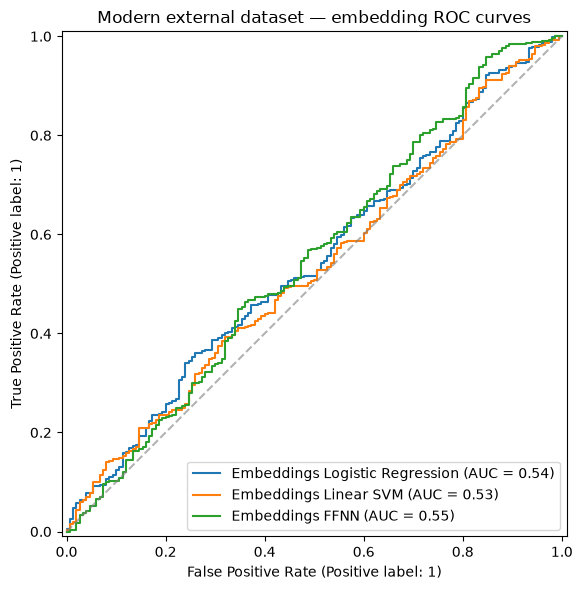

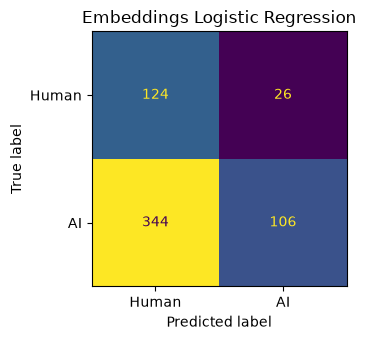

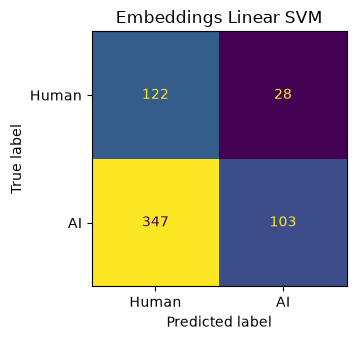

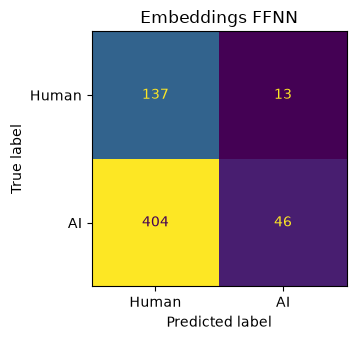

In [18]:
if not results:
    raise RuntimeError('No saved classifiers were found. Check models/embeddings.')
comparison = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(8, 6))
for name, scores in all_scores.items():
    RocCurveDisplay.from_predictions(modern['target'], scores, name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', alpha=0.6)
ax.set_title('Modern external dataset — embedding ROC curves')
plt.tight_layout()
plt.show()

for name, predictions in all_predictions.items():
    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    ConfusionMatrixDisplay.from_predictions(
        modern['target'], predictions, labels=[0, 1],
        display_labels=['Human', 'AI'], ax=ax, colorbar=False,
    )
    ax.set_title(name)
    plt.tight_layout()
    plt.show()


## 7. Break down performance by generator

For human responses, the reported rate is the fraction incorrectly labeled AI. For each AI generator, it is recall (fraction correctly labeled AI).

In [19]:
rows = []
for name, scores in all_scores.items():
    predictions = all_predictions[name]
    for generator in ['human', 'chatgpt', 'claude', 'gemini']:
        mask = modern['model'].astype(str).str.lower().eq(generator).to_numpy()
        if not mask.any():
            continue
        rows.append({
            'model': name,
            'generator': generator,
            'n': int(mask.sum()),
            'metric': 'human_false_positive_rate' if generator == 'human' else 'ai_recall',
            'rate': float(predictions[mask].mean()),
        })
generator_comparison = pd.DataFrame(rows)
display(generator_comparison.round(4))


,model,generator,n,metric,rate
0,Embeddings Logistic Regression,human,150,human_false_positive_rate,0.1733
1,Embeddings Logistic Regression,chatgpt,150,ai_recall,0.2933
2,Embeddings Logistic Regression,claude,150,ai_recall,0.3200
3,Embeddings Logistic Regression,gemini,150,ai_recall,0.0933
4,Embeddings Linear SVM,human,150,human_false_positive_rate,0.1867
5,Embeddings Linear SVM,chatgpt,150,ai_recall,0.2600
6,Embeddings Linear SVM,claude,150,ai_recall,0.3200
7,Embeddings Linear SVM,gemini,150,ai_recall,0.1067
8,Embeddings FFNN,human,150,human_false_positive_rate,0.0867
9,Embeddings FFNN,chatgpt,150,ai_recall,0.1133


## 8. Export embedding results for the later comparison notebook

In [20]:
comparison.to_csv(RESULTS_DIR / 'modern_embeddings_metrics.csv', index=False)
generator_comparison.to_csv(RESULTS_DIR / 'modern_embeddings_generator_metrics.csv', index=False)
prediction_export = modern[['id', 'model', 'label', 'target']].copy()
for name, scores in all_scores.items():
    prefix = name.lower().replace(' ', '_').replace('-', '_')
    prediction_export[f'{prefix}_score'] = scores
    prediction_export[f'{prefix}_prediction'] = all_predictions[name]
prediction_export.to_csv(RESULTS_DIR / 'modern_embeddings_predictions.csv', index=False)
print('Saved results in:', RESULTS_DIR)
print('Models evaluated:', len(results), 'of 3')


Saved results in: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation
Models evaluated: 3 of 3
